# Redundancy and association check (Spearman correlation)

Give a feature CSV (rows = samples, columns = `<image type>_<class>_<feature>`) and run all cells.

* **Redundancy**: two features are redundant if |Spearman rho| >= `THRESHOLD`. Features are grouped so that every
  pair inside a group has |rho| >= `THRESHOLD`; one representative per group is kept (`non_redundant_features.csv`).
* **Association**: mean |rho| between all features of two feature classes (or image types). The diagonal shows
  how redundant a class is internally; off-diagonal cells show how strongly two classes carry the same information.

Spearman is used because it is rank based: it captures any monotonic relation and is robust to the skewed
distributions and outliers of radiomic features.


In [1]:
import sys
from pathlib import Path

CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "pre_processing", "feature_extraction", "post_processing"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

from pathlib import Path
from IPython.display import display
from redundancy import run_redundancy_analysis

FEATURE_DIR = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/features/pyradiomics")
CSV_PATH = FEATURE_DIR / "features_log_filter.csv"      # <- the feature matrix to analyse
OUTPUT_DIR = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy")

import yaml
config_path = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/config_files/setup.yaml")

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config
THRESHOLD = config["THRESHOLD_REDUNDANCY"]      # |rho| at or above this = redundant
CHANNEL = None       # None = all rows; 0, 1, 2 or 3 = only that MRI channel

In [2]:
results = run_redundancy_analysis(CSV_PATH, OUTPUT_DIR, threshold=THRESHOLD, channel=CHANNEL)

/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


features_log_filter: 40 samples, 465 features (0 constant dropped) | 106 redundant pairs (|rho| >= 0.995) | 391 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_log_filter


## Clustered correlation matrix

Red = positive, blue = negative correlation. Large dark blocks are groups of redundant features.
The colour bar on the left gives the feature class of every row.

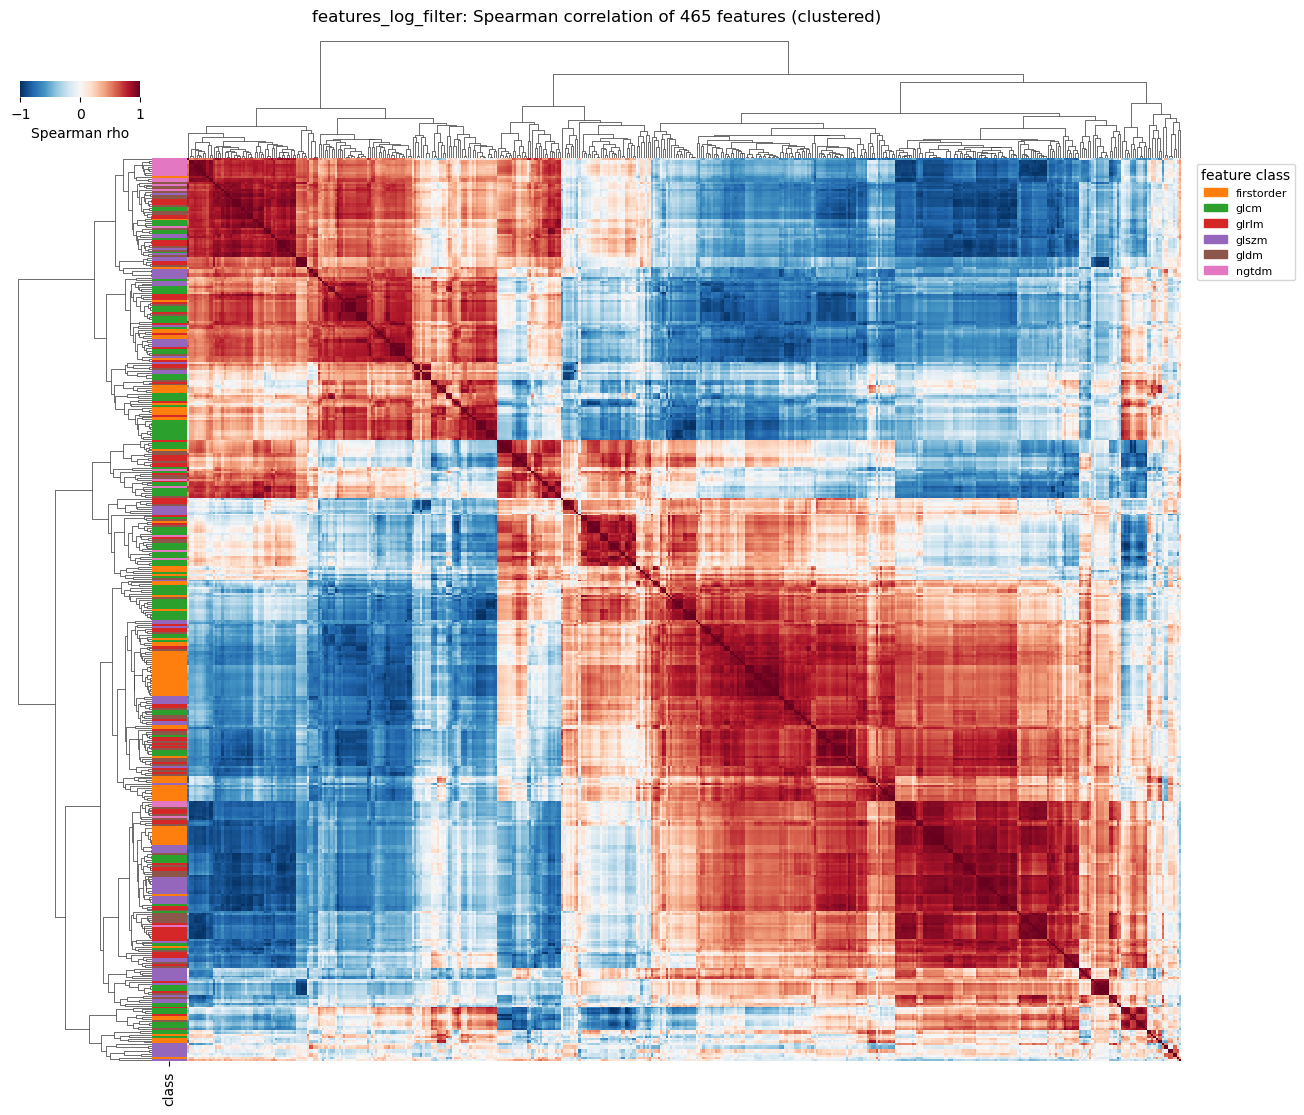

In [3]:
display(results["figures"]["clustermap"])

## Association and redundancy between feature classes

Left: mean |rho| between two classes (high = the classes carry similar information).
Right: % of feature pairs that are redundant (|rho| >= threshold).

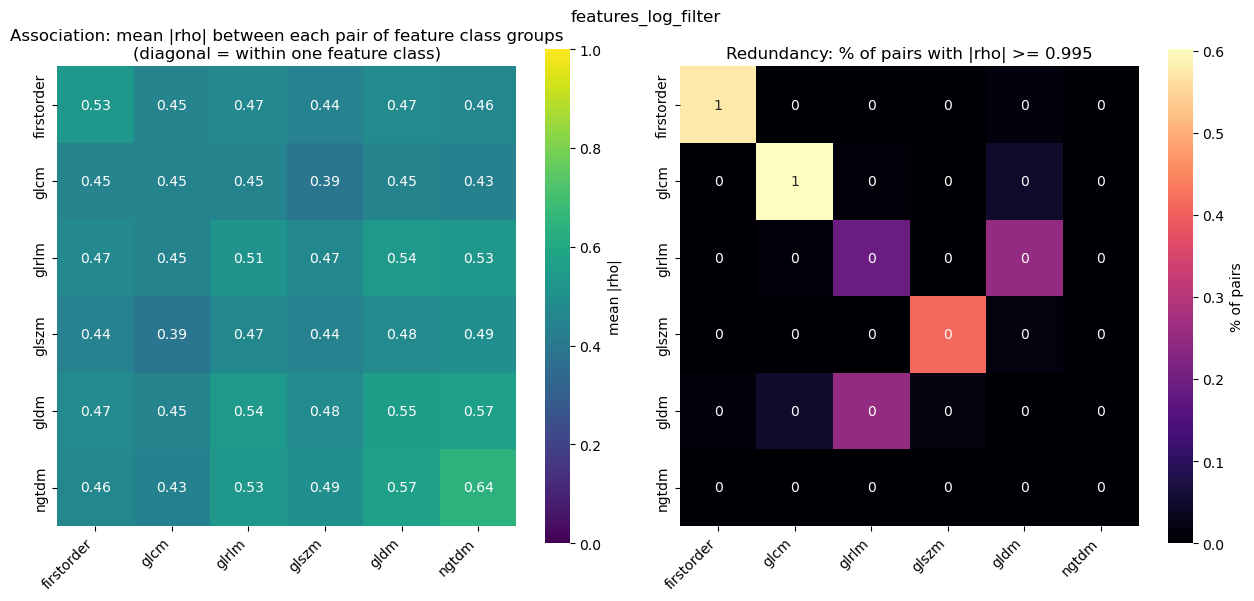

,firstorder,glcm,glrlm,glszm,gldm,ngtdm
firstorder,0.53,0.45,0.47,0.44,0.47,0.46
glcm,0.45,0.45,0.45,0.39,0.45,0.43
glrlm,0.47,0.45,0.51,0.47,0.54,0.53
glszm,0.44,0.39,0.47,0.44,0.48,0.49
gldm,0.47,0.45,0.54,0.48,0.55,0.57
ngtdm,0.46,0.43,0.53,0.49,0.57,0.64


In [4]:
display(results["figures"]["class_association"])
display(results["class_association"].round(2))

## Correlation within vs between classes, and features kept after removing redundancy

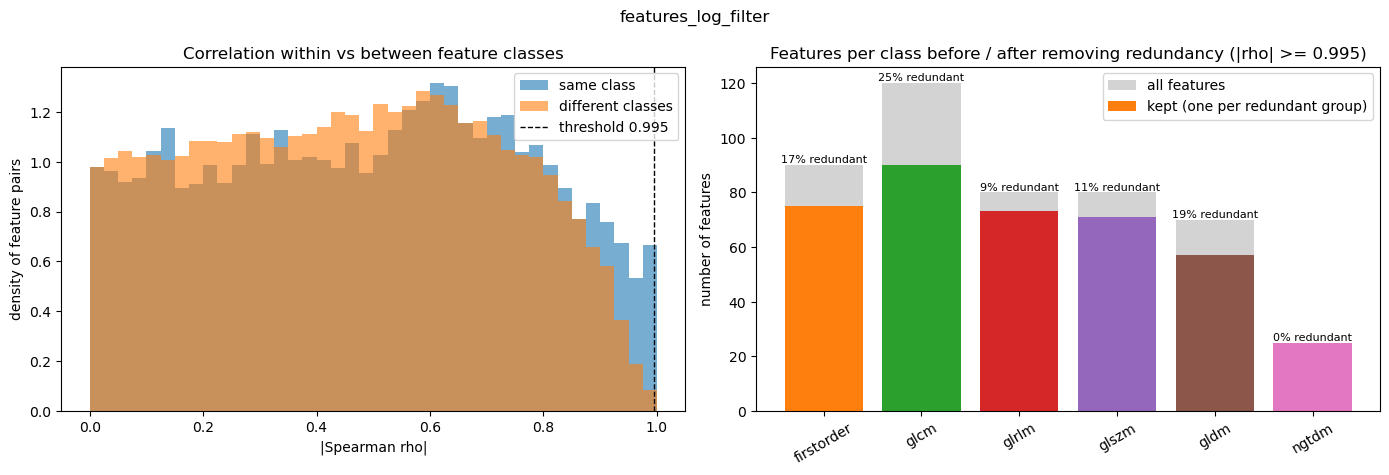

,features,kept,removed,percent_redundant
feature_class,,,,
firstorder,90,75,15,16.7
glcm,120,90,30,25.0
glrlm,80,73,7,8.8
glszm,80,71,9,11.2
gldm,70,57,13,18.6
ngtdm,25,25,0,0.0


In [5]:
display(results["figures"]["overview"])
display(results["class_summary"].round(1))

## Association between image types (only for CSVs with several image types, e.g. wavelet, LoG, Gabor, Laws)

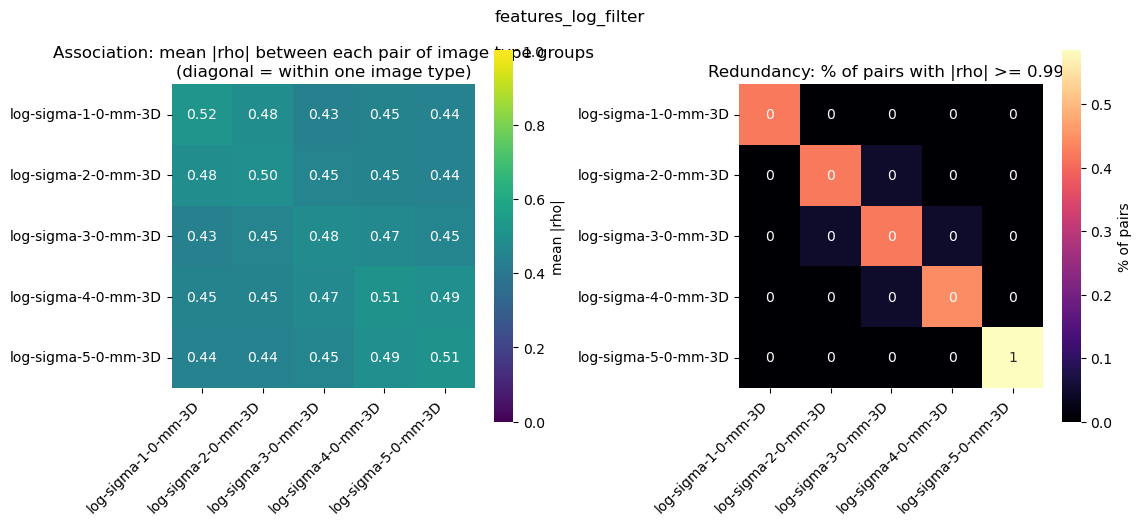

,log-sigma-1-0-mm-3D,log-sigma-2-0-mm-3D,log-sigma-3-0-mm-3D,log-sigma-4-0-mm-3D,log-sigma-5-0-mm-3D
log-sigma-1-0-mm-3D,0.523,0.485,0.431,0.447,0.442
log-sigma-2-0-mm-3D,0.485,0.496,0.449,0.448,0.441
log-sigma-3-0-mm-3D,0.431,0.449,0.478,0.470,0.455
log-sigma-4-0-mm-3D,0.447,0.448,0.470,0.509,0.493
log-sigma-5-0-mm-3D,0.442,0.441,0.455,0.493,0.507


In [6]:
if "image_type_association" in results:
    display(results["figures"]["image_type_association"])
    display(results["image_type_association"].round(3))
else:
    print("only one image type in this CSV")

## Most redundant feature pairs and redundant groups

In [7]:
pairs = results["redundant_pairs"]
print(f"{len(pairs)} redundant pairs, {100 * pairs['same_class'].mean() if len(pairs) else 0:.0f} % of them within the same class")
display(pairs.head(15).round(3))

clusters = results["clusters"]
display(clusters[clusters["cluster_size"] > 1].sort_values("cluster_size", ascending=False).head(20))

106 redundant pairs, 80 % of them within the same class


,feature_1,feature_2,rho,class_1,class_2,same_class
0,log-sigma-1-0-mm-3D_firstorder_Energy,log-sigma-1-0-mm-3D_firstorder_TotalEnergy,1.0,firstorder,firstorder,True
1,log-sigma-2-0-mm-3D_firstorder_Energy,log-sigma-2-0-mm-3D_firstorder_TotalEnergy,1.0,firstorder,firstorder,True
2,log-sigma-3-0-mm-3D_glcm_JointAverage,log-sigma-3-0-mm-3D_glcm_SumAverage,1.0,glcm,glcm,True
3,log-sigma-4-0-mm-3D_firstorder_Energy,log-sigma-4-0-mm-3D_firstorder_TotalEnergy,1.0,firstorder,firstorder,True
4,log-sigma-2-0-mm-3D_glcm_Contrast,log-sigma-2-0-mm-3D_glcm_Idmn,-1.0,glcm,glcm,True
5,log-sigma-1-0-mm-3D_glszm_LargeAreaEmphasis,log-sigma-1-0-mm-3D_glszm_ZoneVariance,1.0,glszm,glszm,True
6,log-sigma-3-0-mm-3D_glcm_DifferenceAverage,log-sigma-3-0-mm-3D_glcm_Idn,-1.0,glcm,glcm,True
7,log-sigma-3-0-mm-3D_glcm_Contrast,log-sigma-3-0-mm-3D_glcm_Idmn,-1.0,glcm,glcm,True
8,log-sigma-4-0-mm-3D_glcm_JointAverage,log-sigma-4-0-mm-3D_glcm_SumAverage,1.0,glcm,glcm,True
9,log-sigma-3-0-mm-3D_firstorder_Energy,log-sigma-3-0-mm-3D_firstorder_TotalEnergy,1.0,firstorder,firstorder,True


,feature,image_type,feature_class,feature_name,cluster,cluster_size,representative
134,log-sigma-3-0-mm-3D_firstorder_TotalEnergy,log-sigma-3-0-mm-3D,firstorder,TotalEnergy,108,4,False
136,log-sigma-4-0-mm-3D_firstorder_TotalEnergy,log-sigma-4-0-mm-3D,firstorder,TotalEnergy,108,4,False
133,log-sigma-3-0-mm-3D_firstorder_Energy,log-sigma-3-0-mm-3D,firstorder,Energy,108,4,True
135,log-sigma-4-0-mm-3D_firstorder_Energy,log-sigma-4-0-mm-3D,firstorder,Energy,108,4,False
339,log-sigma-5-0-mm-3D_glrlm_HighGrayLevelRunEmph...,log-sigma-5-0-mm-3D,glrlm,HighGrayLevelRunEmphasis,284,3,False
228,log-sigma-5-0-mm-3D_glcm_Contrast,log-sigma-5-0-mm-3D,glcm,Contrast,193,3,True
226,log-sigma-4-0-mm-3D_glcm_DifferenceEntropy,log-sigma-4-0-mm-3D,glcm,DifferenceEntropy,191,3,False
225,log-sigma-4-0-mm-3D_glcm_Contrast,log-sigma-4-0-mm-3D,glcm,Contrast,191,3,False
224,log-sigma-4-0-mm-3D_glcm_Idmn,log-sigma-4-0-mm-3D,glcm,Idmn,191,3,True
83,log-sigma-3-0-mm-3D_glrlm_RunVariance,log-sigma-3-0-mm-3D,glrlm,RunVariance,69,3,True


##  Run every feature CSV in the folder

In [8]:
all_results = {}
for csv_path in sorted(FEATURE_DIR.glob("features_*.csv")):
    all_results[csv_path.stem] = run_redundancy_analysis(csv_path, OUTPUT_DIR, threshold=THRESHOLD, channel=CHANNEL)

/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


features_binary_patterns: 40 samples, 275 features (4 constant dropped) | 131 redundant pairs (|rho| >= 0.995) | 201 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_binary_patterns
features_exponential_filter: 40 samples, 93 features (0 constant dropped) | 11 redundant pairs (|rho| >= 0.995) | 82 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_exponential_filter


/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


features_gabor_filter: 40 samples, 372 features (0 constant dropped) | 95 redundant pairs (|rho| >= 0.995) | 310 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_gabor_filter
features_gradient_filter: 40 samples, 93 features (0 constant dropped) | 15 redundant pairs (|rho| >= 0.995) | 80 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_gradient_filter


/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


...

features_log_filter: 40 samples, 465 features (0 constant dropped) | 106 redundant pairs (|rho| >= 0.995) | 391 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_log_filter
features_logarithmic_filter: 40 samples, 93 features (0 constant dropped) | 21 redundant pairs (|rho| >= 0.995) | 79 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_logarithmic_filter


/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


features_raw_image: 40 samples, 107 features (0 constant dropped) | 21 redundant pairs (|rho| >= 0.995) | 92 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_raw_image
features_square_filter: 40 samples, 93 features (0 constant dropped) | 14 redundant pairs (|rho| >= 0.995) | 81 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_square_filter
features_square_root_filter: 40 samples, 93 features (0 constant dropped) | 21 redundant pairs (|rho| >= 0.995) | 79 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_square_root_filter


/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


features_wavelet_filter: 40 samples, 744 features (0 constant dropped) | 165 redundant pairs (|rho| >= 0.995) | 633 non-redundant features kept | saved to /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/features_wavelet_filter


In [9]:
print(all_results)

{'features_binary_patterns': {'features':     lbp-3D-m1_firstorder_10Percentile  lbp-3D-m1_firstorder_90Percentile  \
0                            3.610047                          18.050234   
1                            4.125768                          17.018792   
2                            4.641489                          15.987350   
3                            4.125768                          17.018792   
4                            3.094326                          17.534513   
5                            3.610047                          17.018792   
6                            4.125768                          16.503071   
7                            3.610047                          17.018792   
8                            4.125768                          16.503071   
9                            4.641489                          14.955908   
10                           4.641489                          15.471629   
11                           4.125768         

In [10]:
import pandas as pd
from pathlib import Path

summary_rows = []

for name, result in all_results.items():
    features = result["features"]
    clusters = result["clusters"]
    pairs = result["redundant_pairs"]
    constant = result["constant_features"]

    total_features = features.shape[1]
    kept_features = int(clusters["representative"].sum())
    removed_features = total_features - kept_features

    summary_rows.append({
        "Feature CSV": name,
        "Samples": len(features),
        "Total Features": total_features + len(constant),
        "Constant Features Dropped": len(constant),
        "Features Analyzed": total_features,
        "Redundant Pairs": len(pairs),
        "Redundant Features Removed": removed_features,
        "Non-Redundant Features Kept": kept_features,
        "Retention (%)": round(100 * kept_features / total_features, 2) if total_features else 0,
        "Redundancy (%)": round(100 * removed_features / total_features, 2) if total_features else 0,
        "Spearman Threshold": THRESHOLD
    })

# Create summary DataFrame
redundancy_summary = pd.DataFrame(summary_rows)

# Save CSV
save_path = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/redundancy.csv")
save_path.parent.mkdir(parents=True, exist_ok=True)

redundancy_summary.to_csv(save_path, index=False)

# Display summary
display(redundancy_summary)

print(f"Summary saved to: {save_path}")

,Feature CSV,Samples,Total Features,Constant Features Dropped,Features Analyzed,Redundant Pairs,Redundant Features Removed,Non-Redundant Features Kept,Retention (%),Redundancy (%),Spearman Threshold
0,features_binary_patterns,40,279,4,275,131,74,201,73.09,26.91,0.995
1,features_exponential_filter,40,93,0,93,11,11,82,88.17,11.83,0.995
2,features_gabor_filter,40,372,0,372,95,62,310,83.33,16.67,0.995
3,features_gradient_filter,40,93,0,93,15,13,80,86.02,13.98,0.995
4,features_laws_filter,40,558,0,558,163,90,468,83.87,16.13,0.995
5,features_log_filter,40,465,0,465,106,74,391,84.09,15.91,0.995
6,features_logarithmic_filter,40,93,0,93,21,14,79,84.95,15.05,0.995
7,features_raw_image,40,107,0,107,21,15,92,85.98,14.02,0.995
8,features_square_filter,40,93,0,93,14,12,81,87.10,12.90,0.995
9,features_square_root_filter,40,93,0,93,21,14,79,84.95,15.05,0.995


Summary saved to: /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/redundancy/redundancy.csv
